# Milestone 4: Comparing kNN and a Decision Tree with our Baseline
CSCI 3052U Machine Learning I,
Jason Badwal, Cort Auger, Saad Siddiqui, Adlene Oudahmane

In our Milestone 3 start/stop/continue plan we said we'd fit kNN and a decision tree on the same split and seeds as the baseline, and look for ways to do better on the Enrolled class. This notebook goes through that work. As before, the code lives in `src/`, and this notebook reads the results that `python -m src.compare_models` writes to `results/m4/`:

| File | What it does |
|---|---|
| `src/compare_models.py` | Tunes kNN and a decision tree on validation, refits them on 10 seeds, tests the imbalance fixes, the subgroup check, and saves every table and figure |
| `src/data.py` | Same pipeline as M3, plus `undersample()` (the Lab 2 code from M2 8.1) |
| `results/m4/` | `model_comparison`, `knn_grid`, `tree_grid`, `seed_runs`, `paired_seed_comparison`, `imbalance`, `subgroups`, `error_examples` and the figures |

Where the methods come from:
- [Lab 3] / [Week 3]: kNN with `KNeighborsClassifier`, Euclidean and cosine distance, choosing k on validation, normalization with training-set stats
- [Lab 4] / [Week 3]: decision trees with entropy (information gain) or Gini, the `build_all_models` search over `max_depth` and `min_samples_split`, and the "highest validation score so far" loop
- [Lab 2] / [Week 2]: undersampling the majority classes, on the training set only
- [Week 4] / [Week 5]: the softmax regression baseline from M3, and underfitting vs overfitting

**The test set still isn't used.** Everything here is on the validation set; the test set gets scored once, in Milestone 5.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

%matplotlib inline

sys.path.insert(0, str(Path.cwd().parent))
RESULTS = Path.cwd().parent / "results"
M4 = RESULTS / "m4"

with open(M4 / "chosen.json") as f:
    chosen = json.load(f)
chosen

{'knn': {'k': 7, 'metric': 'euclidean'},
 'tree': {'criterion': 'entropy',
  'max_depth': 12,
  'min_samples_split': 32,
  'actual_depth': 12,
  'leaves': 158},
 'softmax': {'alpha': 0.3, 'lambda': 0, 'n_iters': 5000},
 'best_nonlinear': 'Decision tree',
 'python': '3.13.15',
 'scikit-learn': '1.6.1',
 'command': 'python -m src.compare_models'}

## Part 1 - kNN [Lab 3, Week 3]
kNN predicts the majority class of the $k$ closest training students. We use Euclidean distance from the lecture, $\|\mathbf{x}^{(a)} - \mathbf{x}^{(b)}\|_2 = \sqrt{\sum_j (x_j^{(a)} - x_j^{(b)})^2}$ (W3 p.15), and also cosine distance like we did with the fake-news data in Lab 3. Because kNN is all distances, the continuous features have to be normalized first, which our pipeline already does with the training mean and std.

We tried every odd $k$ from 1 to 55 (W3 p.43 says to keep $k < \sqrt{N}$, and $\sqrt{3096} \approx 55$) with both distances, and picked the pair with the highest validation macro-F1:

In [2]:
knn_grid = pd.read_csv(M4 / "knn_grid.csv")
print(knn_grid.groupby("metric")["valid_macro_f1"].max().round(4))
knn_grid.loc[knn_grid["valid_macro_f1"].idxmax()]

metric
cosine       0.5296
euclidean    0.5537
Name: valid_macro_f1, dtype: float64


metric            euclidean
k                         7
train_macro_f1     0.670835
valid_macro_f1     0.553716
Name: 3, dtype: object

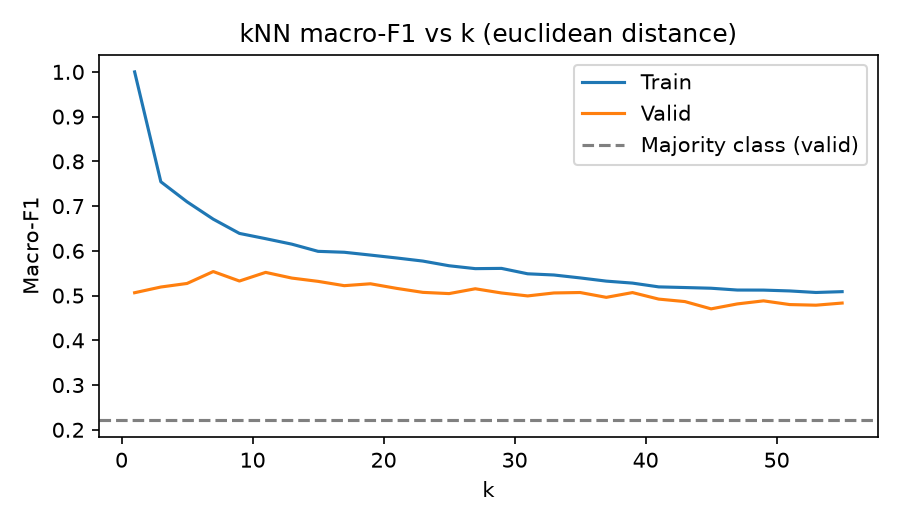

In [3]:
display(Image(M4 / "knn_curve.png"))

**Answer:** The best kNN uses $k = 7$ with Euclidean distance and gets a validation macro-F1 of 0.554. At $k = 1$ it memorizes the training set (train macro-F1 1.00) but only gets 0.51 on validation, which is the overfitting end of the curve. As $k$ goes up the train score drops toward the validation score, but validation never gets much past 0.55.

Our guess for why kNN does badly here is the curse of dimensionality from Week 3: 169 features, and most of them are one-hot columns that are almost always 0. Every student ends up roughly the same distance from everyone else, so the "nearest" neighbours aren't that similar.

## Part 2 - Decision tree [Lab 4, Week 3]
A decision tree picks the split with the biggest information gain, $IG(Y|X) = H(Y) - H(Y|X)$, where $H(Y) = -\sum_y p(y)\log_2 p(y)$ is the entropy (W3 p.101-108). Lab 4 also tried the Gini criterion, so we searched both, with the exact `max_depth` and `min_samples_split` lists from Lab 4 (2 × 14 × 9 = 252 trees). Trees don't need normalized features, because a split only cares about the order of the values (Lab 4), so they get the same inputs as the other models without any problem.

In [4]:
tree_grid = pd.read_csv(M4 / "tree_grid.csv")
best = tree_grid.loc[tree_grid.groupby("criterion")["valid_macro_f1"].idxmax()]
best.round(4)

,criterion,max_depth,min_samples_split,train_macro_f1,valid_macro_f1
85,entropy,12,32,0.7480,0.6344
144,gini,3,2,0.6134,0.6175


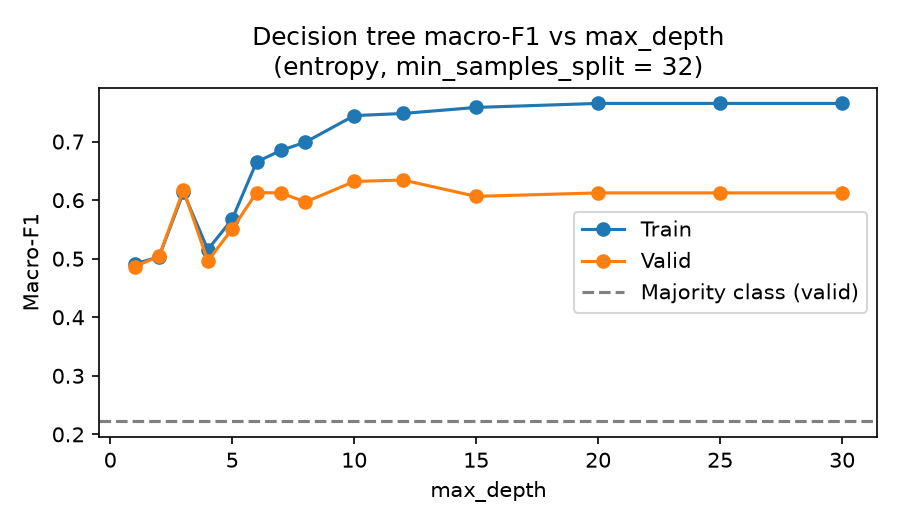

In [5]:
display(Image(M4 / "tree_curve.png"))

**Answer:** The best tree uses entropy, `max_depth = 12` and `min_samples_split = 32` (158 leaves), with a validation macro-F1 of 0.634. Gini's best was a much smaller tree (depth 3) at 0.618.

The depth curve shows the same under/overfitting story as Lab 4: shallow trees underfit, and past depth 12 the training score keeps going up while validation flattens out around 0.61. The train-valid gap at the chosen depth is about 0.11, compared with about 0.04 for softmax regression, so the tree fits the training data harder but doesn't generalize any better.

The bump at depth 3 is in the data: a 3-level tree happens to land close to the best score, then depth 4 drops before deeper trees recover. That's why we don't pick the depth by eye.

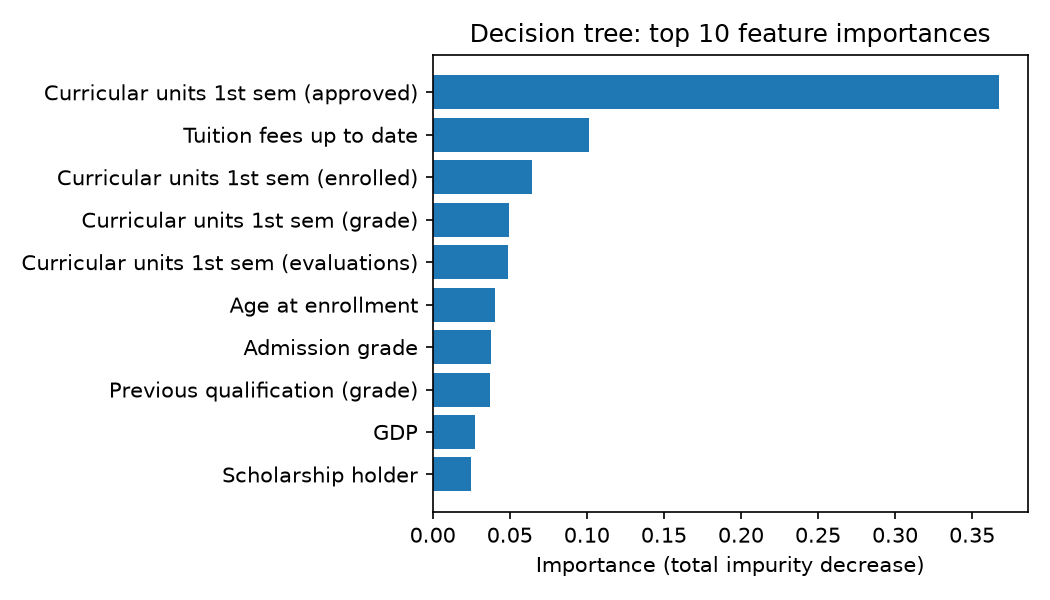

,importance
Curricular units 1st sem (approved),0.368
Tuition fees up to date,0.102
Curricular units 1st sem (enrolled),0.064
Curricular units 1st sem (grade),0.050
Curricular units 1st sem (evaluations),0.049
Age at enrollment,0.040
Admission grade,0.038
Previous qualification (grade),0.037
GDP,0.028
Scholarship holder,0.025


In [6]:
display(Image(M4 / "tree_feature_importance.png"))
pd.read_csv(M4 / "tree_feature_importance.csv", index_col=0).round(3)

**Answer:** Over a third of the tree's total information gain comes from one feature, *Curricular units 1st sem (approved)*, and *Tuition fees up to date* is second. That matches our M2 EDA, where 87% of students who weren't up to date on tuition were Dropouts.

## Part 3 - Comparing the models
Same split (seed 42), same features, and every model tuned on validation only:

In [7]:
table = pd.read_csv(M4 / "model_comparison.csv")
table[["model", "train_macro_f1", "valid_macro_f1", "valid_macro_f1_mean_10_seeds", "valid_macro_f1_std_10_seeds",
       "valid_accuracy", "valid_recall_Dropout", "valid_recall_Enrolled", "fit_seconds"]].round(3)

,model,train_macro_f1,valid_macro_f1,valid_macro_f1_mean_10_seeds,valid_macro_f1_std_10_seeds,valid_accuracy,valid_recall_Dropout,valid_recall_Enrolled,fit_seconds
0,Majority class,0.222,0.222,0.222,0.000,0.500,0.000,0.000,NaN
1,Stratified random,0.329,0.313,0.343,0.012,0.373,0.319,0.126,NaN
2,Softmax regression (M3 baseline),0.705,0.661,0.667,0.020,0.742,0.700,0.353,3.557
3,kNN,0.671,0.554,0.564,0.023,0.645,0.535,0.244,0.002
4,Decision tree,0.748,0.634,0.624,0.018,0.694,0.657,0.429,0.019


One split can be lucky, so we refit each tuned model (without re-tuning) on split seeds 0-9. All the models see the same 10 splits, so we can compare them split by split:

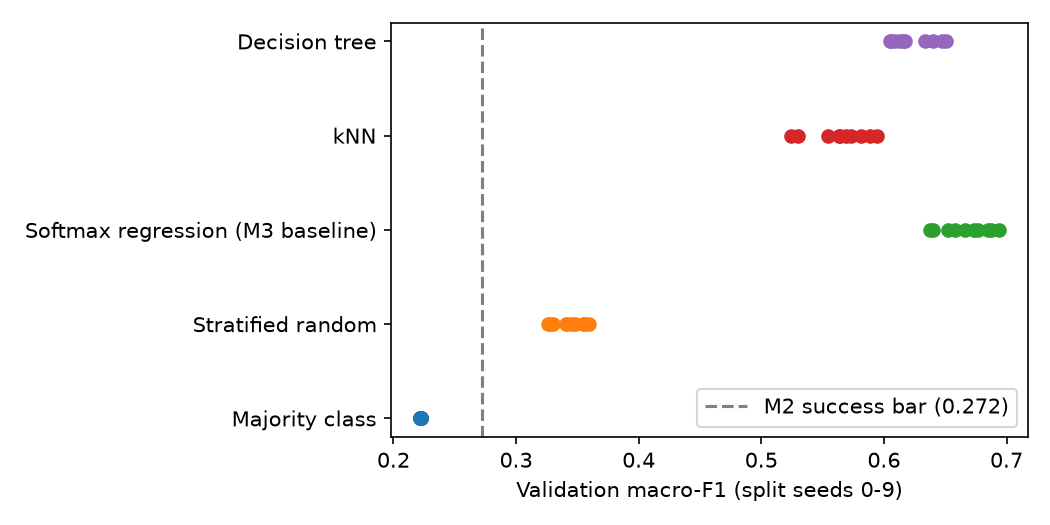

,model_a,model_b,a_wins_out_of_10,mean_diff,std_diff,min_diff,max_diff
0,Softmax regression (M3 baseline),Decision tree,9,0.043,0.027,-0.011,0.078
1,Softmax regression (M3 baseline),kNN,10,0.103,0.023,0.064,0.150
2,Decision tree,kNN,10,0.060,0.018,0.028,0.087


In [8]:
display(Image(M4 / "seed_spread.png"))
pd.read_csv(M4 / "paired_seed_comparison.csv").round(3)

**Answer:** **Neither new model beats the M3 softmax baseline.** Softmax gets 0.667 ± 0.020 over the 10 splits, the tree 0.624 ± 0.018, and kNN 0.564 ± 0.023. Softmax beats the tree on 9 of the 10 splits (by 0.043 on average) and beats kNN on all 10. The tree beats kNN on all 10. Since the gaps hold split after split and are bigger than the seed-to-seed spread, we don't think they're just noise.

This is a negative result for our second question (does a non-linear model help?). On this data the linear decision boundary works better than the two non-linear methods we tried, which fits with the strongest signal being roughly "how many first-semester units did the student pass".

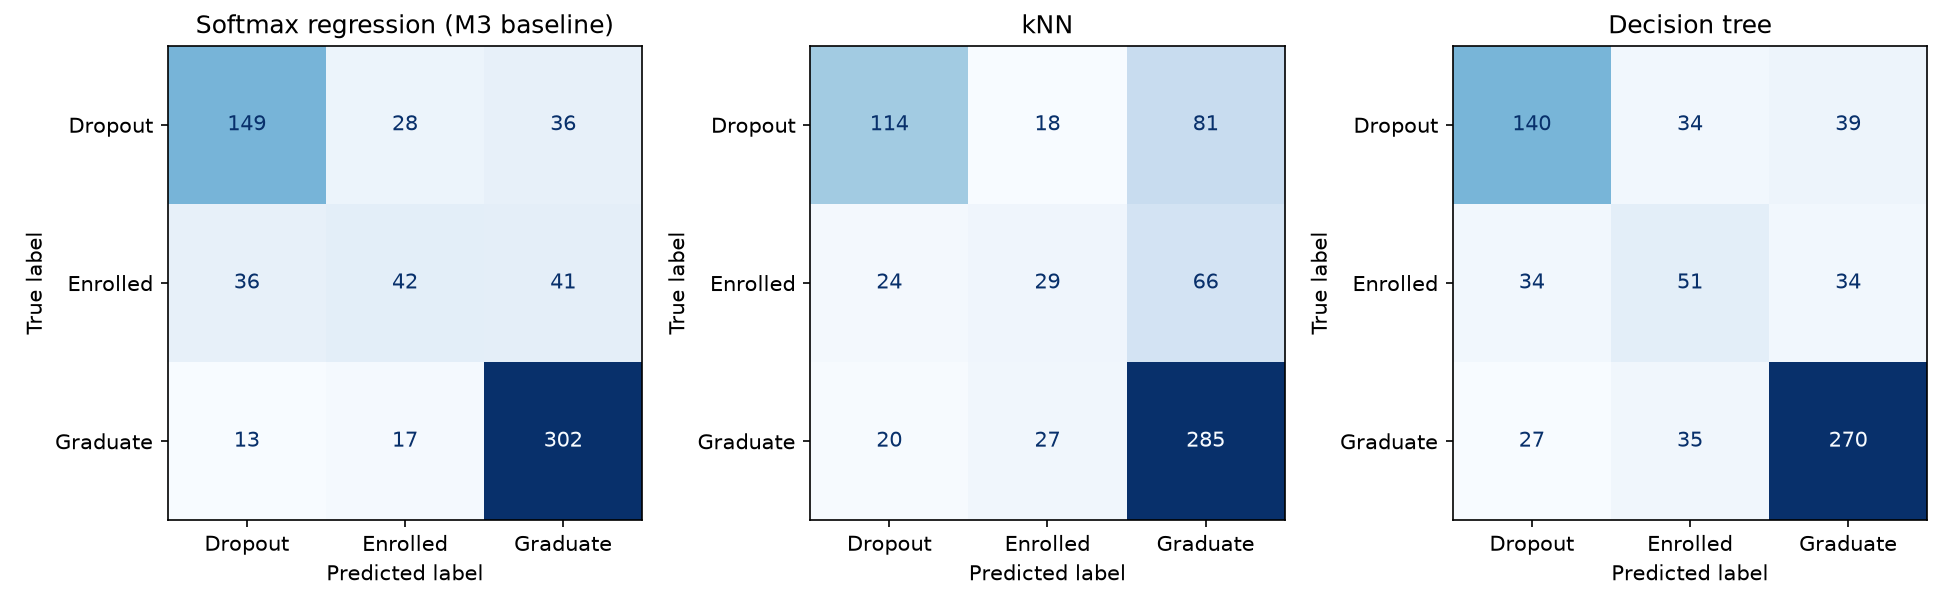

In [9]:
display(Image(M4 / "confusion_all.png"))

**Answer:** All three models are good at Graduate and worst at Enrolled. The tree finds the most Enrolled students (51 of 119, against 42 for softmax), but it also gets more Dropouts and Graduates wrong. kNN sends a lot of Dropouts to Graduate (81 of 213), which is the worst mistake for an early-warning tool because those students wouldn't get flagged at all.

## Part 4 - Can we do better on Enrolled? [Lab 2, Week 2]
In M3 we said we'd try fixing the imbalance for Enrolled (18% of students). We used the Lab 2 undersampling code on the **training set only** (3,096 → 1,668 students, 556 per class), and for the tree we also tried `class_weight="balanced"`, which weights each class by how rare it is instead of throwing data away.

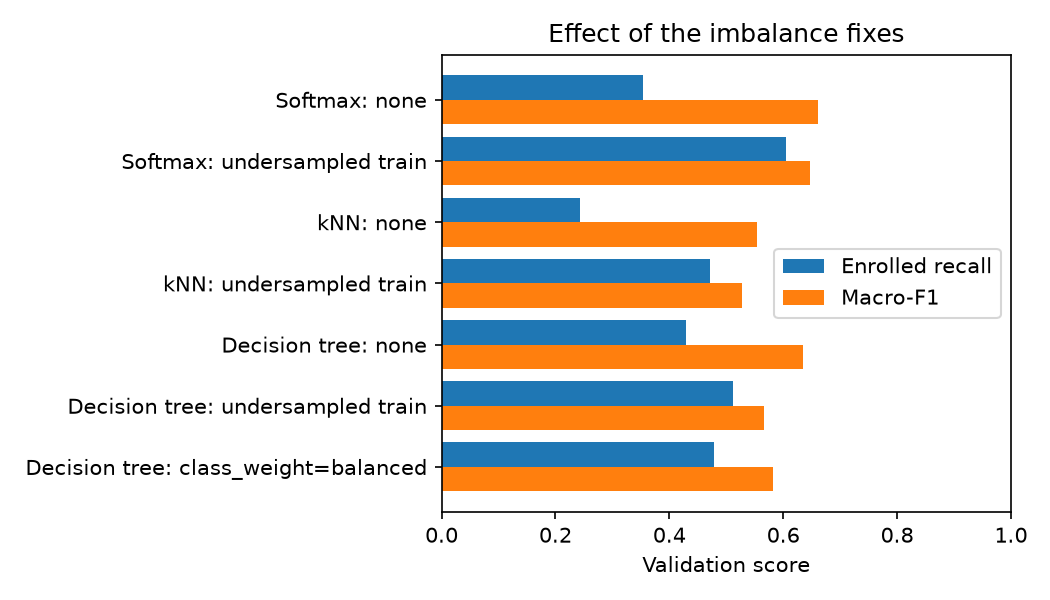

,model,imbalance_fix,n_train,valid_macro_f1,valid_accuracy,recall_Dropout,recall_Enrolled,recall_Graduate,f1_Enrolled
0,Softmax regression (M3 baseline),none,3096,0.661,0.742,0.700,0.353,0.910,0.408
1,Softmax regression (M3 baseline),undersampled train,1668,0.647,0.681,0.648,0.605,0.729,0.462
2,kNN,none,3096,0.554,0.645,0.535,0.244,0.858,0.301
3,kNN,undersampled train,1668,0.528,0.557,0.535,0.471,0.602,0.337
4,Decision tree,none,3096,0.634,0.694,0.657,0.429,0.813,0.427
5,Decision tree,undersampled train,1668,0.566,0.595,0.587,0.513,0.630,0.359
6,Decision tree,class_weight=balanced,3096,0.582,0.627,0.568,0.479,0.717,0.363


In [10]:
display(Image(M4 / "imbalance.png"))
pd.read_csv(M4 / "imbalance.csv").round(3)

**Answer:** Undersampling raises Enrolled recall for every model. Softmax goes from 0.35 to 0.61, and its Enrolled F1 goes from 0.41 to 0.46. The cost is the bigger classes: Graduate recall drops from 0.91 to 0.73, and overall macro-F1 drops a little (0.661 → 0.647).

For kNN and the tree, the drop in macro-F1 is bigger (tree 0.634 → 0.566), so we wouldn't use them that way. Class weights on the tree did better than undersampling it (0.582), but still worse than leaving the tree alone.

If the advising office cares most about catching delayed students, undersampled softmax is the better choice; on our primary metric, the plain model still wins by 0.014. We'll decide in M5 based on the validation set, and keep the primary metric fixed.

## Part 5 - Preliminary subgroup check (M2 §7.6)
Our proposal's success criterion includes checking that the model works about the same for different groups of students. This is a first look on the validation set, with the group size next to every score, since some groups are small:

In [11]:
sub = pd.read_csv(M4 / "subgroups.csv")
sub[sub["model"] == "Softmax regression (M3 baseline)"].drop(columns="model").round(3)

,attribute,group,n,macro_f1,recall_Dropout,recall_Enrolled
0,Gender,female,449,0.660,0.672,0.351
3,Gender,male,215,0.651,0.734,0.357
6,Scholarship holder,no,510,0.654,0.722,0.371
9,Scholarship holder,yes,154,0.629,0.538,0.214
12,Debtor,no,592,0.653,0.655,0.359
15,Debtor,yes,72,0.680,0.897,0.312
18,Tuition fees up to date,no,77,0.497,1.000,0.000
21,Tuition fees up to date,yes,587,0.634,0.570,0.378
24,Previous qualification,secondary,574,0.660,0.671,0.362
27,Previous qualification,other,90,0.641,0.825,0.286


**Answer:** Two things stand out for the softmax baseline:
- **Students behind on tuition (n = 77):** the model predicts Dropout for every single one of them (Dropout recall 1.00, Enrolled recall 0.00). It has basically learned "not paid → dropout", which is mostly right in this data, but it means those students' other information is ignored.
- **Scholarship holders (n = 154):** Dropout recall is 0.54, compared with 0.72 for students without a scholarship. The model misses more of the scholarship students who do drop out, probably because most scholarship holders graduate (76% in our M2 EDA).

Men and women get similar macro-F1 (0.65 vs 0.66). These groups are small, so we're treating this as something to look into in M5.

## Part 6 - Error analysis
Some Enrolled students the tree got wrong, and some Dropouts it got right (raw values, before normalization):

In [12]:
pd.read_csv(M4 / "error_examples.csv", index_col="row_id")

,Course,Age at enrollment,Admission grade,Tuition fees up to date,Scholarship holder,Debtor,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Target,Predicted,model
row_id,,,,,,,,,,,,
3824,9119,18,129.8,1,0,0,5,0,0.000000,Enrolled,Dropout,Decision tree
278,9500,18,142.3,1,1,0,7,7,13.797143,Enrolled,Graduate,Decision tree
908,9238,20,130.0,1,0,0,6,4,11.250000,Enrolled,Graduate,Decision tree
2777,9670,19,122.4,1,0,0,5,4,13.750000,Enrolled,Graduate,Decision tree
2203,171,37,130.0,1,0,0,0,0,0.000000,Dropout,Dropout,Decision tree
1615,9085,26,101.0,1,0,0,6,3,12.666667,Dropout,Dropout,Decision tree


**Answer:** The missed Enrolled students look a lot like the class they were predicted as:
- three of them passed most of their first-semester units with decent grades (for example 7 of 7 approved at 13.8), so the tree called them Graduates
- one passed 0 of 5 units, which looks like a Dropout

Nothing in the first semester tells us these students will end up delayed, which is the hard part of this problem. The Dropouts it caught include a Course 171 student with no recorded units (the `no_units_1st_sem` group from M2) and an older student who passed only half their units.

## Part 7 - What's next
- **For M5:** pick between plain and undersampled softmax on validation, try a small ensemble of trees (bagging, Lab 4) to see if it closes the gap with softmax, extend the subgroup check (parental education, with the group sizes), and score the chosen model on the test set once.
- **Limitations so far:** one institution, a validation set of 664 students (Enrolled has only 119 of them), and the λ = 0 softmax result depends on stopping after 5,000 iterations (M3).

## AI Use Disclosure
Claude Code (Anthropic) helped write `src/compare_models.py`, this notebook and the M4 report and slides. Every number above comes from running `python -m src.compare_models` in this repository.